# Exploratory Data Analysis: Retail Customer Sales (2023-2024)

**Name:** Anurag Srivastava  
**Roll Number / Unique ID:** 2026M01410026  
**Project:** Project 1 - Exploratory Data Analysis

## Objective
Clean and explore retail transaction data, identify data-quality issues, summarize key patterns, and develop practical business insights.

## 1. Setup and First Look

In [1]:
import os, re, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import missingno as msno
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 50); pd.set_option('display.width', 200)
os.makedirs('figures', exist_ok=True); os.makedirs('outputs', exist_ok=True)

raw = pd.read_csv('data/retail_customer_sales_dataset.csv')
df = raw.copy()          # raw is never modified; df is our working copy
print('Shape:', raw.shape)
print('Columns:', list(raw.columns))

Shape: (7084, 24)
Columns: ['Transaction_ID', 'Customer_ID', 'Order_Date', 'Delivery_Date', 'Age', 'Gender', 'Income', 'Region', 'State', 'City', 'Customer_Segment', 'Product_Category', 'Product', 'Quantity', 'Unit_Price', 'Discount', 'Sales', 'Cost', 'Profit', 'Payment_Method', 'Delivery_Mode', 'Customer_Rating', 'Satisfaction_Level', 'Returned']


In [2]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7084 entries, 0 to 7083
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Transaction_ID      7084 non-null   str    
 1   Customer_ID         7084 non-null   str    
 2   Order_Date          7084 non-null   str    
 3   Delivery_Date       6978 non-null   str    
 4   Age                 6942 non-null   float64
 5   Gender              7084 non-null   str    
 6   Income              6831 non-null   float64
 7   Region              7084 non-null   str    
 8   State               7084 non-null   str    
 9   City                7084 non-null   str    
 10  Customer_Segment    7084 non-null   str    
 11  Product_Category    7084 non-null   str    
 12  Product             7084 non-null   str    
 13  Quantity            7084 non-null   int64  
 14  Unit_Price          7084 non-null   float64
 15  Discount            7013 non-null   float64
 16  Sales            

In [3]:
raw.head()

,Transaction_ID,Customer_ID,Order_Date,Delivery_Date,Age,Gender,Income,Region,State,City,Customer_Segment,Product_Category,Product,Quantity,Unit_Price,Discount,Sales,Cost,Profit,Payment_Method,Delivery_Mode,Customer_Rating,Satisfaction_Level,Returned
0,TXN205933,CUST10816,2023-12-19,2023-12-25,38.0,Male,62828.52,West,Gujarat,Surat,Consumer,Grocery,Honey Jar,3,887.94,0.32,1811.40,1204.47,606.93,Debit Card,Standard,3.0,Low,No
1,TXN201247,CUST10916,2023-09-30,2023-10-04,42.0,Male,50952.64,North,Haryana,Gurugram,Home Office,Electronics,USB-C Hub,2,14309.96,0.18,23468.33,17137.06,6331.27,Credit Card,Standard,3.0,High,No
2,TXN202714,CUST11352,2023-01-12,2023-01-20,41.0,Male,60476.00,East,Jharkhand,Ranchi,Consumer,Clothing,Winter Jacket,4,710.95,0.09,2587.86,1577.83,1010.03,Debit Card,Express,3.0,Medium,No
3,TXN206797,CUST11551,2024-06-06,2024-06-10,33.0,Male,41516.94,West,Gujarat,Surat,Home Office,Grocery,Olive Oil 1L,4,332.48,0.34,877.75,556.78,320.97,Debit Card,Standard,3.0,Medium,No
4,TXN203937,CUST10855,2024-09-23,2024-09-30,29.0,Female,95727.49,north,Haryana,Gurugram,Consumer,Electronics,Laptop Stand,1,10542.13,0.21,8328.28,5528.47,2799.81,UPI,Express,1.0,Low,No


In [4]:
raw.tail()

,Transaction_ID,Customer_ID,Order_Date,Delivery_Date,Age,Gender,Income,Region,State,City,Customer_Segment,Product_Category,Product,Quantity,Unit_Price,Discount,Sales,Cost,Profit,Payment_Method,Delivery_Mode,Customer_Rating,Satisfaction_Level,Returned
7079,TXN201768,CUST10870,2024-10-22,2024-10-27,34.0,Male,79446.58,East,Odisha,Bhubaneswar,Corporate,Electronics,Laptop Stand,1,5395.38,0.09,4909.80,3273.47,1636.33,Net Banking,Express,2.0,Low,Yes
7080,TXN201737,CUST10314,2024-10-05,2024-10-14,50.0,Male,21796.92,East,West Bengal,Durgapur,Home Office,Clothing,Formal Shirt,3,1603.82,0.02,4715.23,2923.68,1791.55,Credit Card,Standard,4.0,High,No
7081,TXN203240,CUST10859,2024-06-04,2024-06-15,42.0,Male,60621.27,West,Gujarat,Surat,Consumer,Electronics,Laptop Stand,1,11519.59,0.22,8985.28,5360.01,3625.27,UPI,Standard,2.0,Medium,No
7082,TXN205305,CUST10829,2024-03-31,2024-04-08,32.0,Female,42178.47,South,Kerala,Kozhikode,Consumer,Clothing,Running Shoes,3,980.67,0.21,2324.19,1812.17,512.02,UPI,Standard,4.0,High,No
7083,TXN204737,CUST10847,2024-10-18,2024-10-26,63.0,Male,44113.29,South,Kerala,Kozhikode,Consumer,Clothing,Denim Jacket,2,3727.59,0.30,5218.63,3932.52,1286.11,Debit Card,Standard,4.0,High,No


## 2. Data Quality Audit

### 2.1 Missing values (count and %)

In [5]:
miss = pd.DataFrame({'missing_count': raw.isna().sum(), 'missing_pct': (raw.isna().mean()*100).round(2)})
miss = miss[miss.missing_count > 0].sort_values('missing_count', ascending=False)
miss

,missing_count,missing_pct
Customer_Rating,428,6.04
Income,253,3.57
Satisfaction_Level,179,2.53
Age,142,2.00
Delivery_Date,106,1.50
Discount,71,1.00


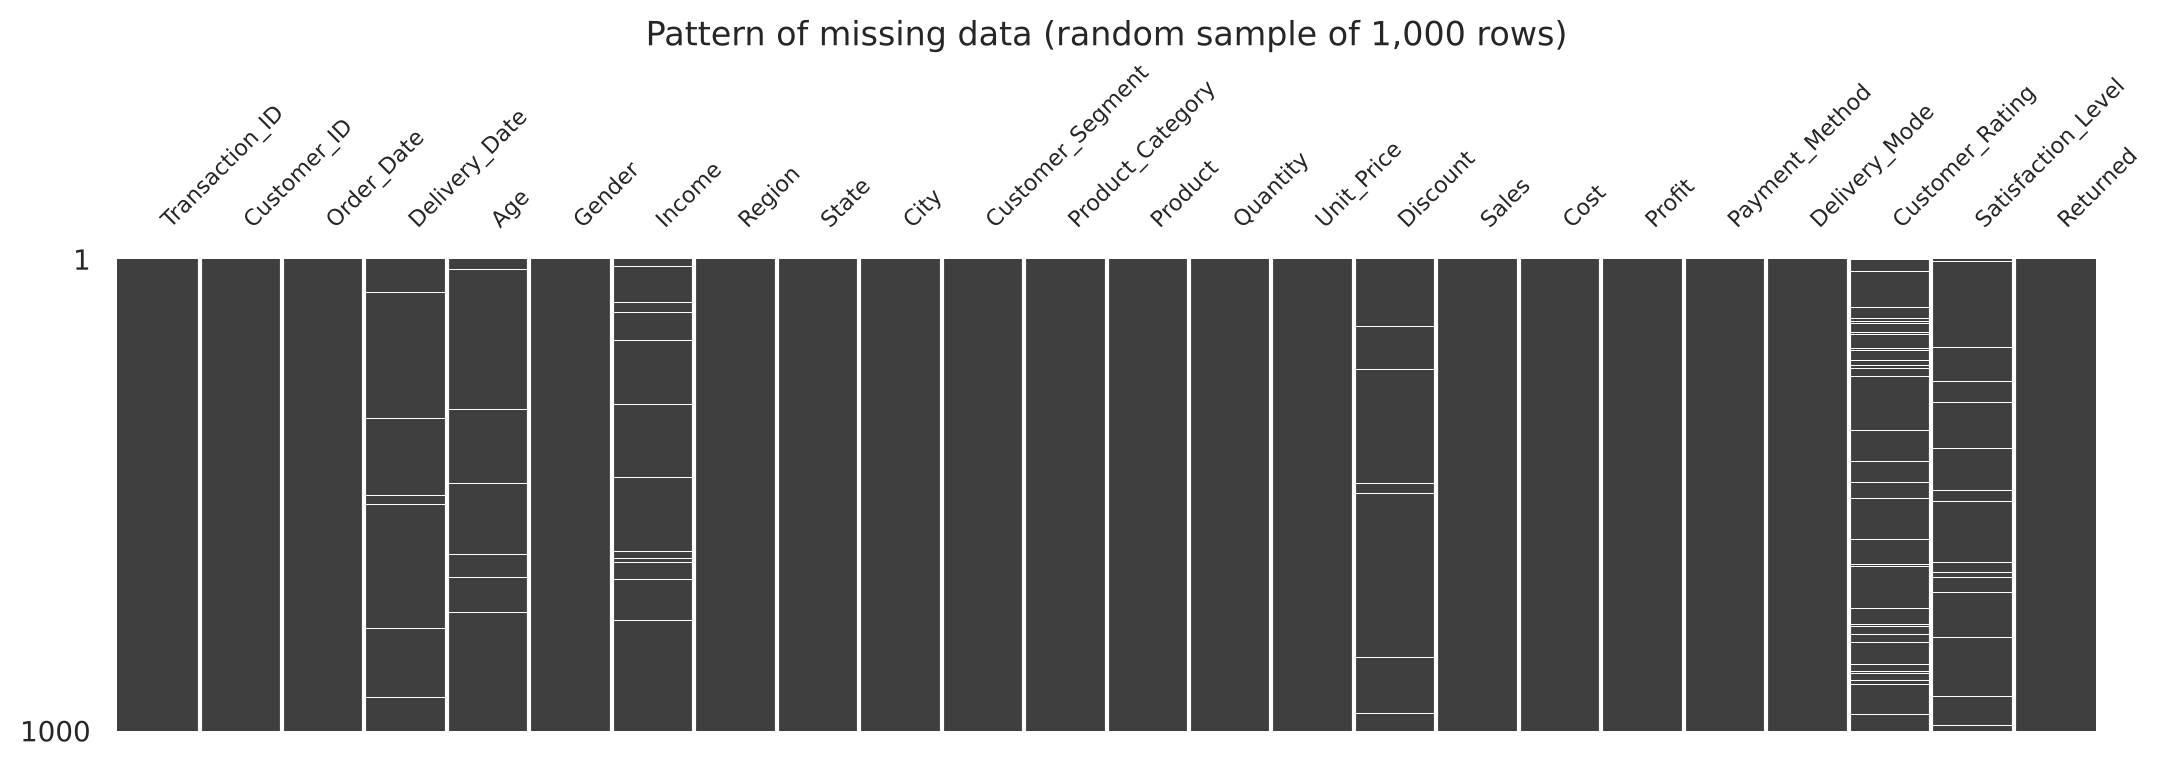

In [6]:
fig, ax = plt.subplots(figsize=(11,4))
msno.matrix(raw.sample(1000, random_state=1), ax=ax, sparkline=False, fontsize=8)
plt.title('Pattern of missing data (random sample of 1,000 rows)')
plt.tight_layout(); plt.savefig('figures/01_missing_pattern.png', dpi=130); plt.show()

**Reading:** Missing values sit in 6 columns (largest: Customer_Rating 6.0%, Income 3.6%) (`Delivery_Date`, `Age`, `Income`, `Discount`, `Customer_Rating`, `Satisfaction_Level`). They are scattered rather than clustered in blocks, so they look random, not caused by one broken data source.

### 2.2 Duplicates

In [7]:
print('Exact duplicate rows (raw):', raw.duplicated().sum())
print('Rows whose Transaction_ID repeats (raw):', raw.Transaction_ID.duplicated().sum())
near = raw[raw.Transaction_ID.duplicated(keep=False) & ~raw.duplicated(keep=False)].sort_values('Transaction_ID')
print('Rows sharing a Transaction_ID but NOT identical:', len(near))
near[['Transaction_ID','Order_Date','Delivery_Date','Gender','Region']].head(8)

Exact duplicate rows (raw): 61
Rows whose Transaction_ID repeats (raw): 84
Rows sharing a Transaction_ID but NOT identical: 46


,Transaction_ID,Order_Date,Delivery_Date,Gender,Region
1227,TXN200162,22/07/2024,26/07/2024,Female,South
1386,TXN200162,2024-07-22,2024-07-26,Female,South
3392,TXN200221,2023-06-23,2023-06-29,female,West
6761,TXN200221,2023-06-23,2023-06-29,Female,West
3719,TXN200275,30/06/2024,03/07/2024,Male,NORTH
2682,TXN200275,30-Jun-2024,03-Jul-2024,Male,North
1713,TXN200750,2024-02-11,2024-02-15,female,Sth
2679,TXN200750,2024-02-11,2024-02-15,Female,South


**Reading:** Besides exact duplicates, there are repeated Transaction_IDs whose rows differ slightly. Likely cause: the same record re-entered with different date format / spelling. We re-check after standardising (Section 3).

### 2.3 Inconsistent categories

In [8]:
for c in ['Gender','Region']:
    print(c, '->', raw[c].value_counts().to_dict(), '\n')
for c in ['Customer_Segment','Product_Category','Payment_Method','Delivery_Mode','Satisfaction_Level','Returned']:
    print(c, '->', raw[c].value_counts(dropna=False).to_dict())

Gender -> {'Female': 3585, 'Male': 3232, 'FEMALE': 53, 'female': 53, 'male': 46, 'MALE': 44, 'M': 38, 'F': 33} 

Region -> {'West': 1783, 'East': 1754, 'South': 1741, 'North': 1647, 'east': 30, 'south': 24, 'north': 21, 'Sth': 20, 'WEST': 19, 'Nort': 17, 'west': 15, 'NORTH': 13} 

Customer_Segment -> {'Consumer': 3899, 'Corporate': 2134, 'Home Office': 1051}
Product_Category -> {'Electronics': 1998, 'Grocery': 1686, 'Clothing': 1558, 'Furniture': 991, 'Office Supplies': 851}
Payment_Method -> {'Net Banking': 1447, 'Debit Card': 1441, 'UPI': 1427, 'Cash on Delivery': 1420, 'Credit Card': 1349}
Delivery_Mode -> {'Standard': 4296, 'Express': 2081, 'Same-Day': 707}
Satisfaction_Level -> {'High': 2581, 'Medium': 2545, 'Low': 1779, nan: 179}
Returned -> {'No': 6190, 'Yes': 894}


**Reading:** `Gender` has 8 labels for 2 real values (Male/Female/MALE/female/M/F...) and `Region` has 12 labels for 4 regions (`Sth`, `Nort`, `north`, `WEST`...). All other categoricals are clean.

### 2.4 Impossible / out-of-range values

In [9]:
rules = {
 'Age < 0 or > 100'            : ((raw.Age < 0) | (raw.Age > 100)).sum(),
 'Age < 18 (valid range)'      : ((raw.Age >= 0) & (raw.Age < 18)).sum(),
 'Discount < 0 or > 0.5'       : ((raw.Discount < 0) | (raw.Discount > 0.5)).sum(),
 'Quantity <= 0'               : (raw.Quantity <= 0).sum(),
 'Unit_Price <= 0'             : (raw.Unit_Price <= 0).sum(),
 'Sales <= 0'                  : (raw.Sales <= 0).sum(),
 'Negative Profit'             : (raw.Profit < 0).sum(),
 'Profit != Sales - Cost'      : ((raw.Sales - raw.Cost - raw.Profit).abs() > 1).sum(),
}
pd.Series(rules, name='rows').to_frame()

,rows
Age < 0 or > 100,6
Age < 18 (valid range),0
Discount < 0 or > 0.5,6
Quantity <= 0,0
Unit_Price <= 0,0
Sales <= 0,0
Negative Profit,0
Profit != Sales - Cost,0


In [10]:
print('Invalid ages   :', sorted(raw.Age[(raw.Age<0)|(raw.Age>100)].tolist()))
print('Invalid discount:', sorted(raw.Discount[(raw.Discount<0)|(raw.Discount>0.5)].tolist()))
calc = raw.Quantity * raw.Unit_Price * (1 - raw.Discount)
bad = raw[(calc - raw.Sales).abs() > 1]
print('\nRows where Sales != Qty x Price x (1-Discount):', len(bad))
bad[['Quantity','Unit_Price','Discount','Sales']]

Invalid ages   : [-12.0, -5.0, -1.0, 150.0, 180.0, 999.0]
Invalid discount: [-0.2, -0.1, 1.1, 1.2, 1.5, 2.0]

Rows where Sales != Qty x Price x (1-Discount): 6


,Quantity,Unit_Price,Discount,Sales
1196,3,2084.63,-0.2,4252.65
2624,5,12394.56,2.0,55155.79
3165,4,977.82,1.1,3598.38
4174,4,9160.38,1.5,33343.78
5410,3,324.04,-0.1,505.50
6693,5,1052.47,1.2,5209.73


**Reading:** 6 impossible ages (-12, -5, -1, 150, 180, 999) and 6 impossible discounts (-0.2 ... 2.0). The 6 rows where the Sales formula breaks are *exactly* the 6 invalid-discount rows, so **Sales is trustworthy and the Discount value is the error**. This allows an exact repair later.

### 2.5 Date format issues

In [11]:
def pattern(s):
    return re.sub(r'[A-Za-z]', 'a', re.sub(r'\d', '9', str(s)))
print('Order_Date formats   :', raw.Order_Date.map(pattern).value_counts().to_dict())
print('Delivery_Date formats:', raw.Delivery_Date.dropna().map(pattern).value_counts().to_dict())
raw.Order_Date[raw.Order_Date.map(pattern) != '9999-99-99'].sample(6, random_state=2).tolist()

Order_Date formats   : {'9999-99-99': 6601, '99-aaa-9999': 161, '99/99/9999': 161, '99-99-9999': 161}
Delivery_Date formats: {'9999-99-99': 6509, '99-aaa-9999': 158, '99/99/9999': 156, '99-99-9999': 155}


['04/03/2024',
 '29-Jul-2023',
 '02-Mar-2023',
 '10-09-2024',
 '05-24-2024',
 '06-30-2024']

**Reading:** Four formats are mixed: ISO `2024-05-19`, `18-Jul-2023`, `20/04/2024` (day-first) and `02-21-2024` (month-first, e.g. 21 cannot be a month). Each format is mapped to its own parsing rule, because blindly using `pd.to_datetime` would swap day/month silently.

## 3. Data Cleaning
Every step records its *why*. Order of operations matters: **standardise first, de-duplicate second** (otherwise slightly-different copies of one record are missed).

### 3.1 Standardise categories

In [12]:
gender_map = {'m':'Male','male':'Male','f':'Female','female':'Female'}
df['Gender'] = df.Gender.str.strip().str.lower().map(gender_map)

region_map = {'north':'North','nort':'North','south':'South','sth':'South','east':'East','west':'West'}
df['Region'] = df.Region.str.strip().str.lower().map(region_map)

assert df.Gender.notna().all() and df.Region.notna().all()
print(df.Gender.value_counts().to_dict()); print(df.Region.value_counts().to_dict())

{'Female': 3724, 'Male': 3360}
{'West': 1817, 'South': 1785, 'East': 1784, 'North': 1698}


**Why:** Pure spelling/casing variants of the same value; mapping to one label is lossless. The `assert` guarantees nothing fell outside the mapping.

### 3.2 Parse dates into datetime

In [13]:
def parse_date(s):
    if pd.isna(s): return pd.NaT
    s = str(s).strip()
    p = pattern(s)
    if p == '9999-99-99': return pd.to_datetime(s, format='%Y-%m-%d')
    if p == '99-aaa-9999': return pd.to_datetime(s, format='%d-%b-%Y')
    if p == '99/99/9999': return pd.to_datetime(s, format='%d/%m/%Y')   # day-first
    if p == '99-99-9999': return pd.to_datetime(s, format='%m-%d-%Y')   # month-first
    return pd.NaT

df['Order_Date'] = df.Order_Date.map(parse_date)
df['Delivery_Date'] = df.Delivery_Date.map(parse_date)
print('Unparsed Order_Date  :', df.Order_Date.isna().sum())
print('Order range  :', df.Order_Date.min().date(), 'to', df.Order_Date.max().date())
print('Delivery range:', df.Delivery_Date.min().date(), 'to', df.Delivery_Date.max().date())
print(df[['Order_Date','Delivery_Date']].dtypes)

Unparsed Order_Date  : 0
Order range  : 2023-01-01 to 2024-12-31
Delivery range: 2023-01-02 to 2025-01-13
Order_Date       datetime64[us]
Delivery_Date    datetime64[us]
dtype: object


**Why:** Every Order_Date parsed with zero failures and all fall within 2023-2024, confirming the day/month rules were applied correctly. 106 blank Delivery_Dates stay `NaT` (handled in 3.6).

### 3.3 Duplicates

In [14]:
print('Exact duplicates BEFORE standardising :', raw.duplicated().sum())
print('Exact duplicates AFTER  standardising :', df.duplicated().sum())
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print('Rows dropped:', before - len(df), '| rows left:', len(df))
print('Repeated Transaction_ID remaining:', df.Transaction_ID.duplicated().sum())

Exact duplicates BEFORE standardising : 61
Exact duplicates AFTER  standardising : 84
Rows dropped: 84 | rows left: 7000
Repeated Transaction_ID remaining: 0


**Why:** A transaction ID is unique by definition, so repeated rows are the same sale counted twice and would inflate revenue. Standardising first revealed extra hidden duplicates that exact matching on raw data missed. After de-duplication every Transaction_ID is unique.

### 3.4 Impossible numeric values

In [15]:
# Age: invalid -> NaN, then filled from the SAME customer's other valid records (Age is constant per customer)
df['Age_Invalid_Flag'] = (df.Age < 0) | (df.Age > 100)
df.loc[df.Age_Invalid_Flag, 'Age'] = np.nan

# Discount: invalid -> recompute exactly from the Sales identity
df['Discount_Invalid_Flag'] = (df.Discount < 0) | (df.Discount > 0.5)
implied = 1 - df.Sales / (df.Quantity * df.Unit_Price)
df.loc[df.Discount_Invalid_Flag, 'Discount'] = implied[df.Discount_Invalid_Flag].round(2)
print('Invalid ages flagged     :', df.Age_Invalid_Flag.sum())
print('Invalid discounts fixed  :', df.Discount_Invalid_Flag.sum())
print('Repaired discounts:', df.loc[df.Discount_Invalid_Flag, 'Discount'].tolist())

Invalid ages flagged     : 6
Invalid discounts fixed  : 6
Repaired discounts: [0.32, 0.11, 0.08, 0.09, 0.48, 0.01]


**Why:** An age of 999 or a discount of 200% is a typo, not a real extreme. Setting to missing (instead of keeping or capping) stops it distorting averages. The discount is mathematically recoverable, so we repair it exactly rather than guess.

### 3.5 Missing values: column-by-column decision

In [16]:
# Age: constant per customer -> fill from customer's other rows, then median for customers with no valid age
print('Customers with >1 distinct Age:', (df.groupby('Customer_ID').Age.nunique() > 1).sum())
df['Age_Imputed_Flag'] = df.Age.isna()
df['Age'] = df.Age.fillna(df.groupby('Customer_ID').Age.transform('median'))
df['Age'] = df.Age.fillna(df.Age.median())

# Income: right-skewed -> use MEDIAN (not mean); customer's own value first, then segment median
df['Income_Imputed_Flag'] = df.Income.isna()
df['Income'] = df.Income.fillna(df.groupby('Customer_ID').Income.transform('median'))
df['Income'] = df.Income.fillna(df.groupby('Customer_Segment').Income.transform('median'))

# Discount (genuinely missing): recompute from Sales identity
miss_d = df.Discount.isna()
df.loc[miss_d, 'Discount'] = implied[miss_d].round(2).clip(0, 0.5)
print('Discounts recovered from Sales formula:', miss_d.sum())

# Delivery_Date: NOT imputed -> a made-up delivery date would be fabricated data. Flag it.
df['Delivery_Missing_Flag'] = df.Delivery_Date.isna()

# Customer_Rating: NOT imputed -> a rating is a customer's opinion; flag instead.
df['Rated_Flag'] = df.Customer_Rating.notna()

# Satisfaction_Level: new explicit category 'Not Provided'
df['Satisfaction_Level'] = df.Satisfaction_Level.fillna('Not Provided')
df.isna().sum()[lambda s: s > 0]

Customers with >1 distinct Age: 0
Discounts recovered from Sales formula: 70


Delivery_Date      105
Customer_Rating    420
dtype: int64

| Column | Missing | Treatment | Justification |
|---|---|---|---|
| Age | 142 + 6 invalid | Same customer's other rows -> overall median | Age is identical across a customer's orders; distribution near-symmetric so median is safe |
| Income | 253 | Customer's own value -> segment median | Highly right-skewed; mean would be dragged up by extreme earners |
| Discount | 71 + 6 invalid | Recomputed from Sales = Qty x Price x (1-Disc) | Exact recovery, not an estimate |
| Delivery_Date | 106 | **Left blank + flag** | Inventing a date would fabricate data; Delivery_Days stays NaN |
| Customer_Rating | 428 | **Left blank + flag** | Opinion data; imputing fakes customer sentiment |
| Satisfaction_Level | 179 | New category `Not Provided` | Keeps rows, avoids guessing an ordinal opinion |

### 3.6 Date logic errors

In [17]:
df['Date_Error_Flag'] = df.Delivery_Date < df.Order_Date
print('Delivery earlier than Order:', df.Date_Error_Flag.sum(), 'rows')
df.loc[df.Date_Error_Flag, ['Transaction_ID','Order_Date','Delivery_Date']].head()

Delivery earlier than Order: 15 rows


,Transaction_ID,Order_Date,Delivery_Date
90,TXN200298,2024-05-31,2024-05-30
960,TXN204390,2024-05-24,2024-05-21
1617,TXN204546,2023-02-13,2023-02-09
1730,TXN205018,2024-05-25,2024-05-21
1890,TXN200982,2023-12-06,2023-12-05


**Why:** Goods cannot arrive before they are ordered. We keep the row (its sales/profit are valid) but flag it, and later set `Delivery_Days` to NaN for these rows so they do not produce negative delivery times.

### 3.7 Validate and save cleaned data

In [18]:
print('Final shape:', df.shape, '| raw shape:', raw.shape)
assert df.Transaction_ID.is_unique
assert df.Age.between(0, 100).all() and df.Discount.between(0, 0.5).all()
assert (df.Quantity * df.Unit_Price * (1 - df.Discount) - df.Sales).abs().max() < 1.5
df.to_csv('outputs/cleaned_retail_customer_sales.csv', index=False)
print('Saved -> outputs/cleaned_retail_customer_sales.csv')
cleaning_log = pd.DataFrame([
 ['Duplicate rows removed', before - len(df)],
 ['Gender/Region labels standardised', int((raw.Gender.str.lower().isin(['male','female']).eq(False)).sum() + (~raw.Region.isin(['North','South','East','West'])).sum())],
 ['Invalid ages set to missing', int(df.Age_Invalid_Flag.sum())],
 ['Invalid discounts repaired', int(df.Discount_Invalid_Flag.sum())],
 ['Dates with Delivery < Order (flagged)', int(df.Date_Error_Flag.sum())],
], columns=['Action','Rows affected']); cleaning_log

Final shape: (7000, 31) | raw shape: (7084, 24)


Saved -> outputs/cleaned_retail_customer_sales.csv


,Action,Rows affected
0,Duplicate rows removed,84
1,Gender/Region labels standardised,230
2,Invalid ages set to missing,6
3,Invalid discounts repaired,6
4,Dates with Delivery < Order (flagged),15


## 4. Descriptive Statistics and Univariate Analysis

### 4.1 Descriptive statistics

In [19]:
key = ['Age','Income','Quantity','Unit_Price','Discount','Sales','Cost','Profit']
stats_tbl = pd.DataFrame({
  'mean': df[key].mean(), 'median': df[key].median(), 'mode': df[key].mode().iloc[0],
  'std': df[key].std(), 'variance': df[key].var(),
  'Q1': df[key].quantile(.25), 'Q3': df[key].quantile(.75),
  'IQR': df[key].quantile(.75) - df[key].quantile(.25),
  'P5': df[key].quantile(.05), 'P95': df[key].quantile(.95), 'P99': df[key].quantile(.99),
  'skew': df[key].skew(), 'kurtosis': df[key].kurt()}).round(2)
stats_tbl

,mean,median,mode,std,variance,Q1,Q3,IQR,P5,P95,P99,skew,kurtosis
Age,36.05,36.00,18.00,10.41,1.083000e+02,29.00,43.00,14.00,18.00,54.00,62.00,0.27,-0.31
Income,55049.38,48846.62,15000.00,36971.39,1.366883e+09,37125.40,65721.73,28596.33,23778.87,102537.52,157204.63,17.54,679.96
Quantity,3.01,3.00,2.00,1.41,1.990000e+00,2.00,4.00,2.00,1.00,6.00,7.00,0.73,0.58
Unit_Price,4519.23,2261.47,122.04,4893.21,2.394348e+07,895.92,7244.50,6348.58,294.23,14629.96,18687.23,1.26,0.47
Discount,0.20,0.18,0.13,0.12,1.000000e-02,0.11,0.27,0.16,0.04,0.43,0.50,0.64,-0.24
Sales,10961.60,4825.56,258.73,14549.03,2.116744e+08,1815.46,14095.34,12279.89,498.35,41542.62,66961.38,2.40,7.29
Cost,7371.90,3229.88,217.28,9878.00,9.757487e+07,1210.18,9494.70,8284.52,337.45,28045.80,44925.03,2.47,7.89
Profit,3589.70,1528.70,19.47,4928.02,2.428538e+07,574.08,4533.28,3959.20,153.66,13749.64,22969.86,2.59,8.83


**Business reading:** For Income, Sales, Cost and Profit the **mean is clearly above the median**, a sign of right skew: most transactions are modest, while a small number of large orders pull the average up. For these columns the median describes a "typical" transaction better than the mean. Age is nearly symmetric (mean ~ median).

### 4.2 Distribution shape of numerical variables

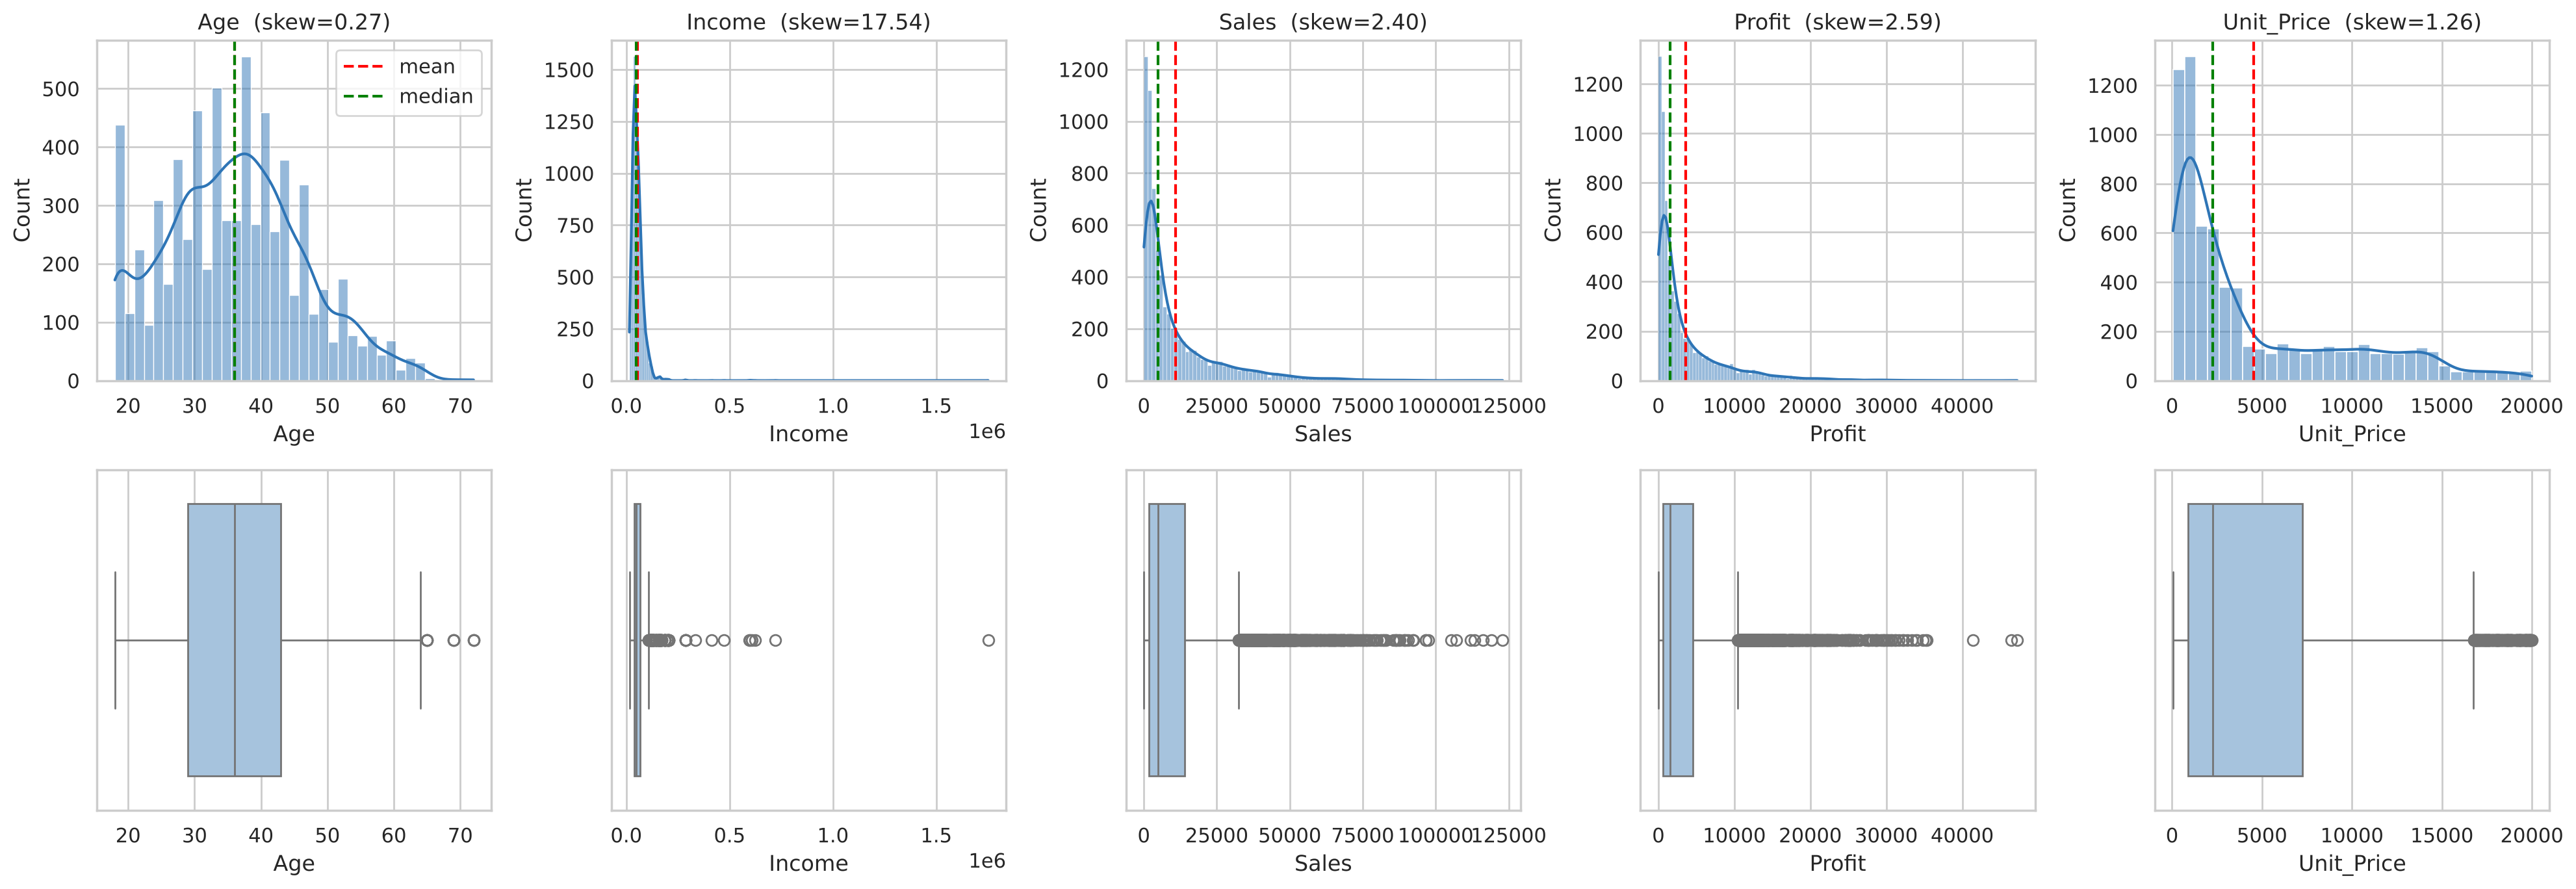

,skewness,shape
Age,0.27,approximately symmetric
Income,17.54,right-skewed
Sales,2.40,right-skewed
Profit,2.59,right-skewed
Unit_Price,1.26,right-skewed


In [20]:
num_plot = ['Age','Income','Sales','Profit','Unit_Price']
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for i, c in enumerate(num_plot):
    sns.histplot(df[c], kde=True, ax=axes[0, i], color='#2E75B6'); axes[0, i].set_title(f'{c}  (skew={df[c].skew():.2f})')
    axes[0,i].axvline(df[c].mean(), color='red', ls='--', label='mean'); axes[0,i].axvline(df[c].median(), color='green', ls='--', label='median')
    sns.boxplot(x=df[c], ax=axes[1, i], color='#9DC3E6')
axes[0,0].legend()
plt.tight_layout(); plt.savefig('figures/02_numeric_distributions.png', dpi=130); plt.show()
def shape(sk):
    return 'approximately symmetric' if abs(sk) < 0.5 else ('right-skewed' if sk > 0 else 'left-skewed')
pd.DataFrame({'skewness': df[num_plot].skew().round(2), 'shape': [shape(s) for s in df[num_plot].skew()]})

**What the skew means in business terms**
- **Age** - roughly symmetric: the customer base is a normal spread around the mid-30s; the mean is a fair summary.
- **Income** - strongly right-skewed: most customers earn moderate incomes, a few very high earners exist. Use the median, not the mean, for segmentation or targeting.
- **Sales / Profit** - right-skewed: revenue depends on a minority of big-ticket orders (e.g. electronics or furniture, higher quantities). Losing a few such orders hurts far more than losing many small ones.

### 4.3 Categorical frequency and proportion

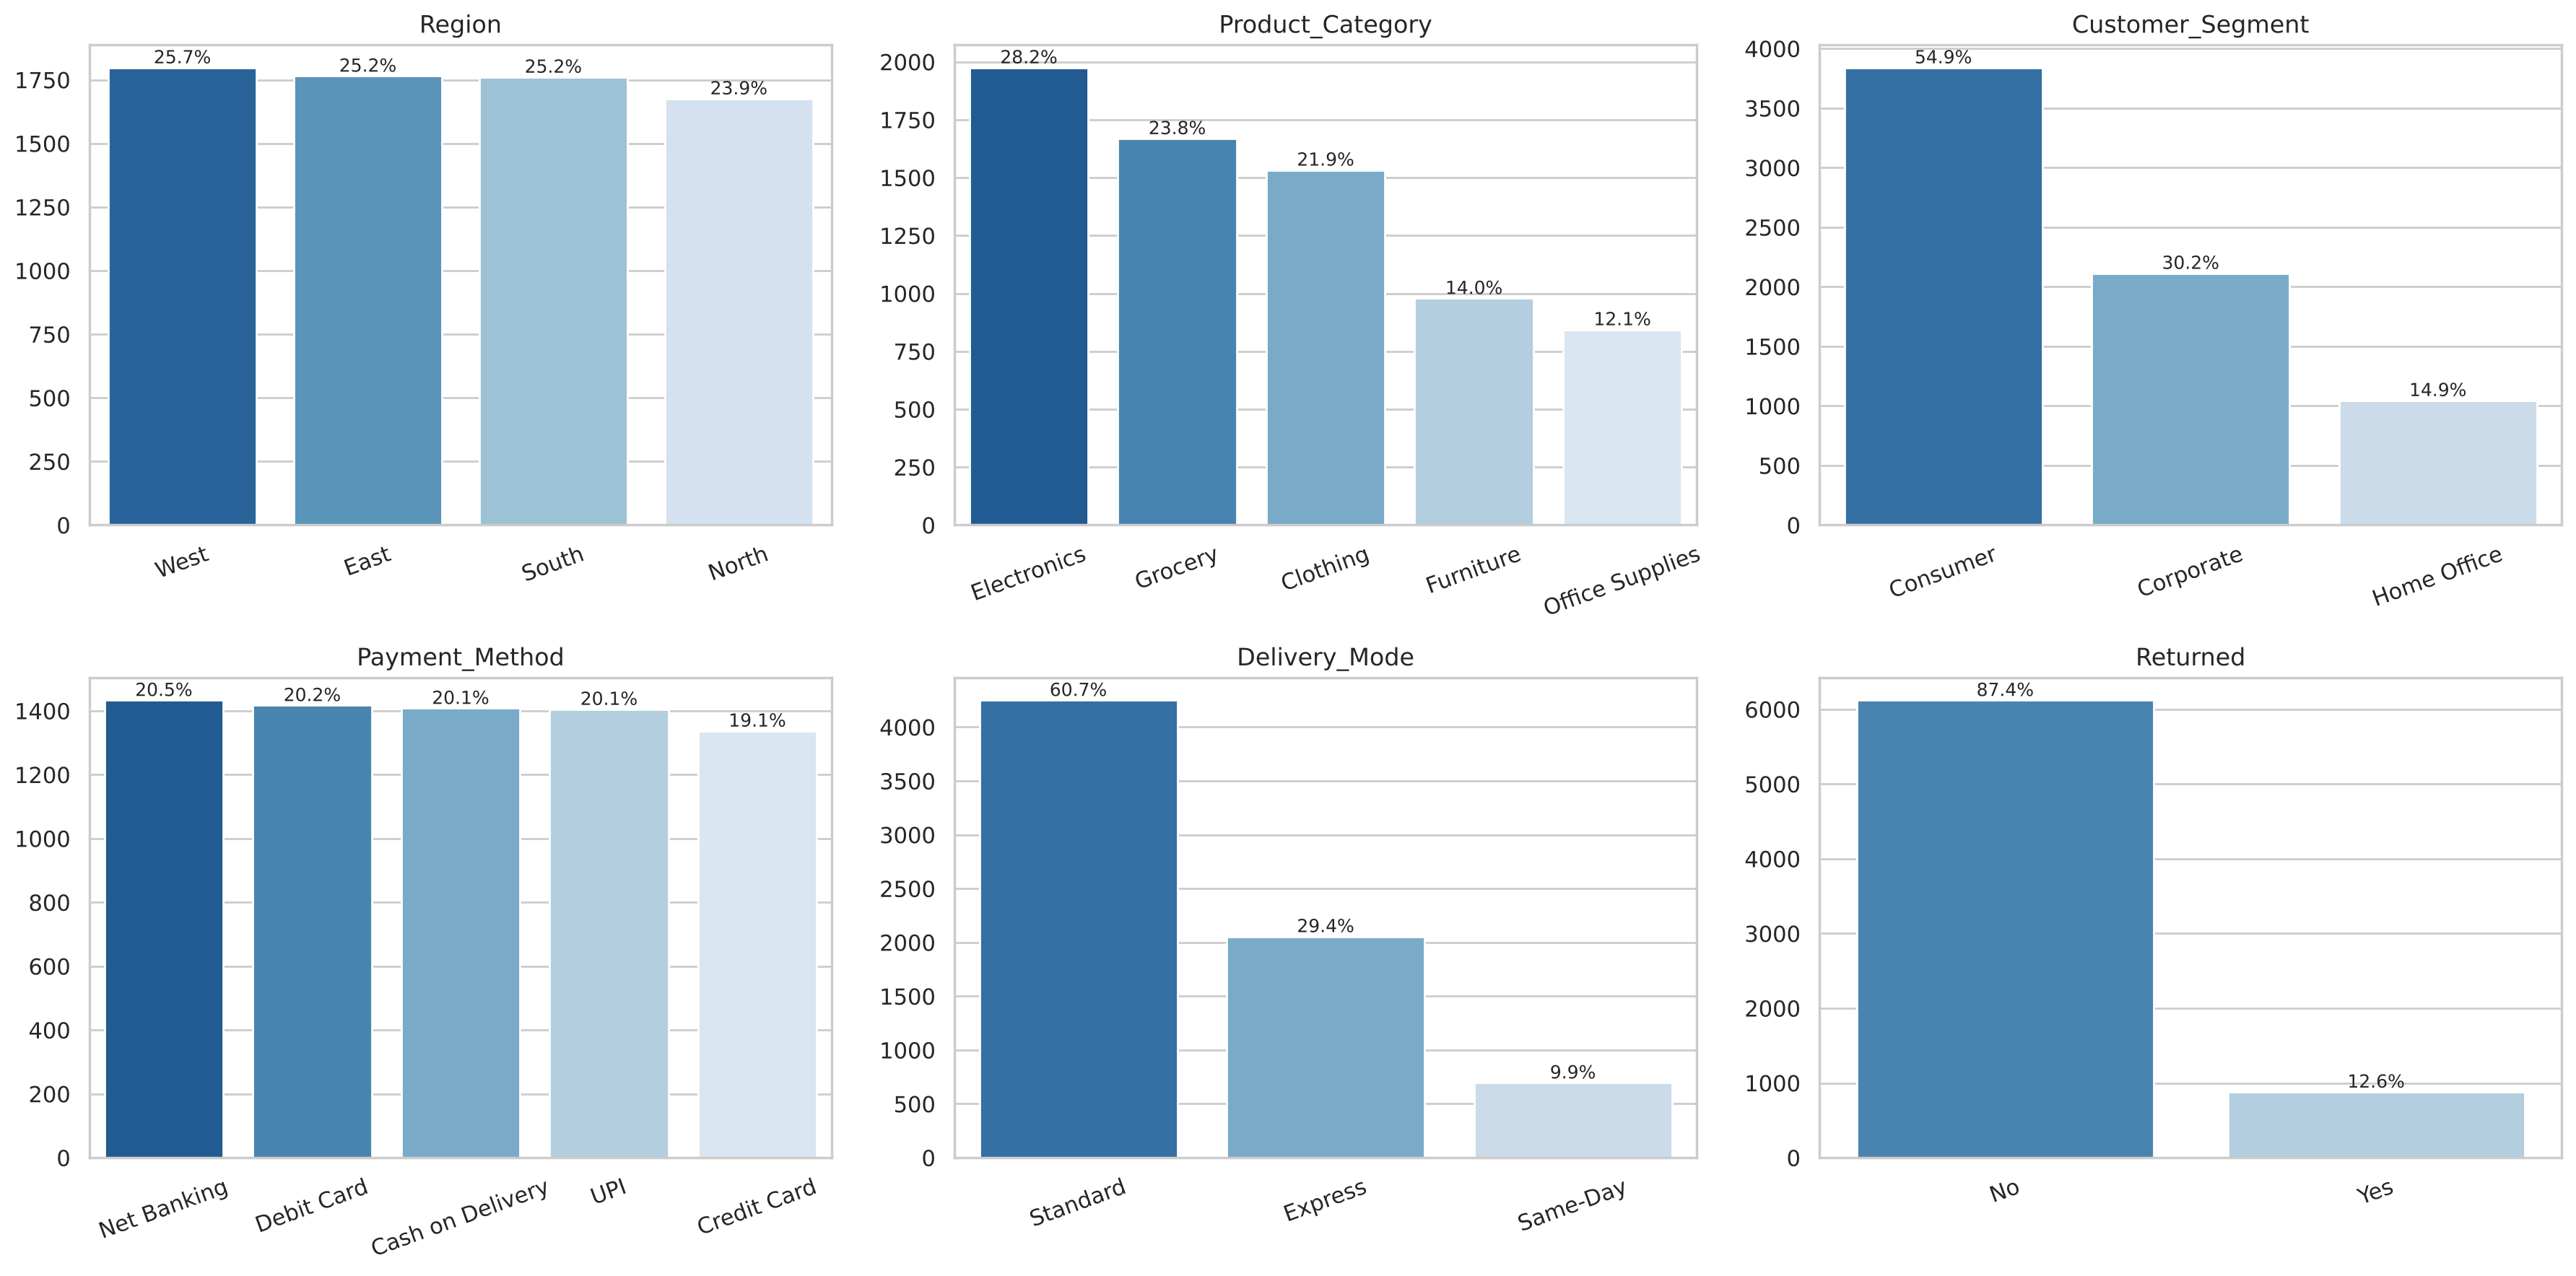

In [21]:
cats = ['Region','Product_Category','Customer_Segment','Payment_Method','Delivery_Mode','Returned']
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, c in zip(axes.flat, cats):
    vc = df[c].value_counts()
    sns.barplot(x=vc.index, y=vc.values, ax=ax, palette='Blues_r')
    for p, v in zip(ax.patches, vc.values):
        ax.annotate(f'{v/len(df):.1%}', (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom', fontsize=9)
    ax.set_title(c); ax.tick_params(axis='x', rotation=20); ax.set_xlabel('')
plt.tight_layout(); plt.savefig('figures/03_categorical_frequencies.png', dpi=130); plt.show()

In [22]:
for c in ['Region','Product_Category','Customer_Segment']:
    t = df[c].value_counts().to_frame('count'); t['proportion_%'] = (t['count']/len(df)*100).round(1)
    display(t)

,count,proportion_%
Region,,
West,1798,25.7
East,1765,25.2
South,1761,25.2
North,1676,23.9


,count,proportion_%
Product_Category,,
Electronics,1975,28.2
Grocery,1669,23.8
Clothing,1533,21.9
Furniture,979,14.0
Office Supplies,844,12.1


,count,proportion_%
Customer_Segment,,
Consumer,3840,54.9
Corporate,2114,30.2
Home Office,1046,14.9


**Reading:** Regions are very evenly balanced (no single region dominates the order count). `Consumer` is the largest segment (~55% of orders) and Electronics the largest category. About 12.6% of orders are returned.

## 5. Outlier Detection

In [23]:
def iqr_bounds(s):
    q1, q3 = s.quantile(.25), s.quantile(.75); i = q3 - q1
    return q1 - 1.5*i, q3 + 1.5*i
rows = []
for c in ['Sales','Profit','Age','Income']:
    lo, hi = iqr_bounds(df[c]); z = (df[c] - df[c].mean()) / df[c].std()
    rows.append([c, round(lo,1), round(hi,1), ((df[c]<lo)|(df[c]>hi)).sum(), (z.abs()>3).sum(),
                 round(((df[c]<lo)|(df[c]>hi)).mean()*100,2)])
outlier_tbl = pd.DataFrame(rows, columns=['Variable','IQR lower','IQR upper','IQR outliers','|Z|>3 outliers','IQR %']); outlier_tbl

,Variable,IQR lower,IQR upper,IQR outliers,|Z|>3 outliers,IQR %
0,Sales,-16604.4,32515.2,632,153,9.03
1,Profit,-5364.7,10472.1,640,160,9.14
2,Age,8.0,64.0,10,6,0.14
3,Income,-5769.1,108616.2,236,41,3.37


In [24]:
# Who are the Sales / Profit outliers?
lo, hi = iqr_bounds(df.Sales)
so = df[df.Sales > hi]
print('Sales outliers:', len(so))
print(so.Product_Category.value_counts(normalize=True).round(2).to_dict())
print('Mean quantity  - outliers vs rest:', round(so.Quantity.mean(),1), 'vs', round(df[df.Sales<=hi].Quantity.mean(),1))
print('Mean unit price- outliers vs rest:', round(so.Unit_Price.mean()), 'vs', round(df[df.Sales<=hi].Unit_Price.mean()))
print('Do outliers obey Sales = Qty x Price x (1-Disc)? max error:', ((so.Quantity*so.Unit_Price*(1-so.Discount)) - so.Sales).abs().max().round(2))

Sales outliers: 632
{'Electronics': 0.53, 'Furniture': 0.47}
Mean quantity  - outliers vs rest: 4.4 vs 2.9
Mean unit price- outliers vs rest: 13602 vs 3618
Do outliers obey Sales = Qty x Price x (1-Disc)? max error: 0.01


In [25]:
lo_i, hi_i = iqr_bounds(df.Income)
io = df[df.Income > hi_i]
print('Income outliers:', len(io), '| largest 5:', io.Income.nlargest(5).round(0).tolist())
print('Median income of outliers by segment:'); print(io.groupby('Customer_Segment').Income.median().round(0).to_dict())
print('Income > 5 x median:', (df.Income > 5*df.Income.median()).sum())

Income outliers: 236 | largest 5: [1750890.0, 721082.0, 622290.0, 606985.0, 598321.0]
Median income of outliers by segment:
{'Consumer': 124659.0, 'Corporate': 123679.0, 'Home Office': 125529.0}
Income > 5 x median: 14


**Decisions (genuine vs error)**

| Variable | Finding | Decision |
|---|---|---|
| **Sales / Profit** | High values come from large Quantity x high Unit_Price (mostly Electronics/Furniture); the arithmetic identity holds exactly | **Genuine extremes - keep.** They are real big orders |
| **Age** | After fixing 6 impossible values (-12 ... 999), remaining ages lie in 18-72 (10 customers above 64 are flagged by IQR but are normal older shoppers) | **Genuine - keep.** Invalid ones were errors and already treated in 3.4 |
| **Income** | Skewed upper tail of high earners; a handful of values several times beyond the next largest (e.g. ~1.75M vs ~0.72M) | **Mostly genuine (income is naturally log-normal); the few extreme values are flagged as suspicious** - kept, but medians/log-scale are used so they cannot distort conclusions |

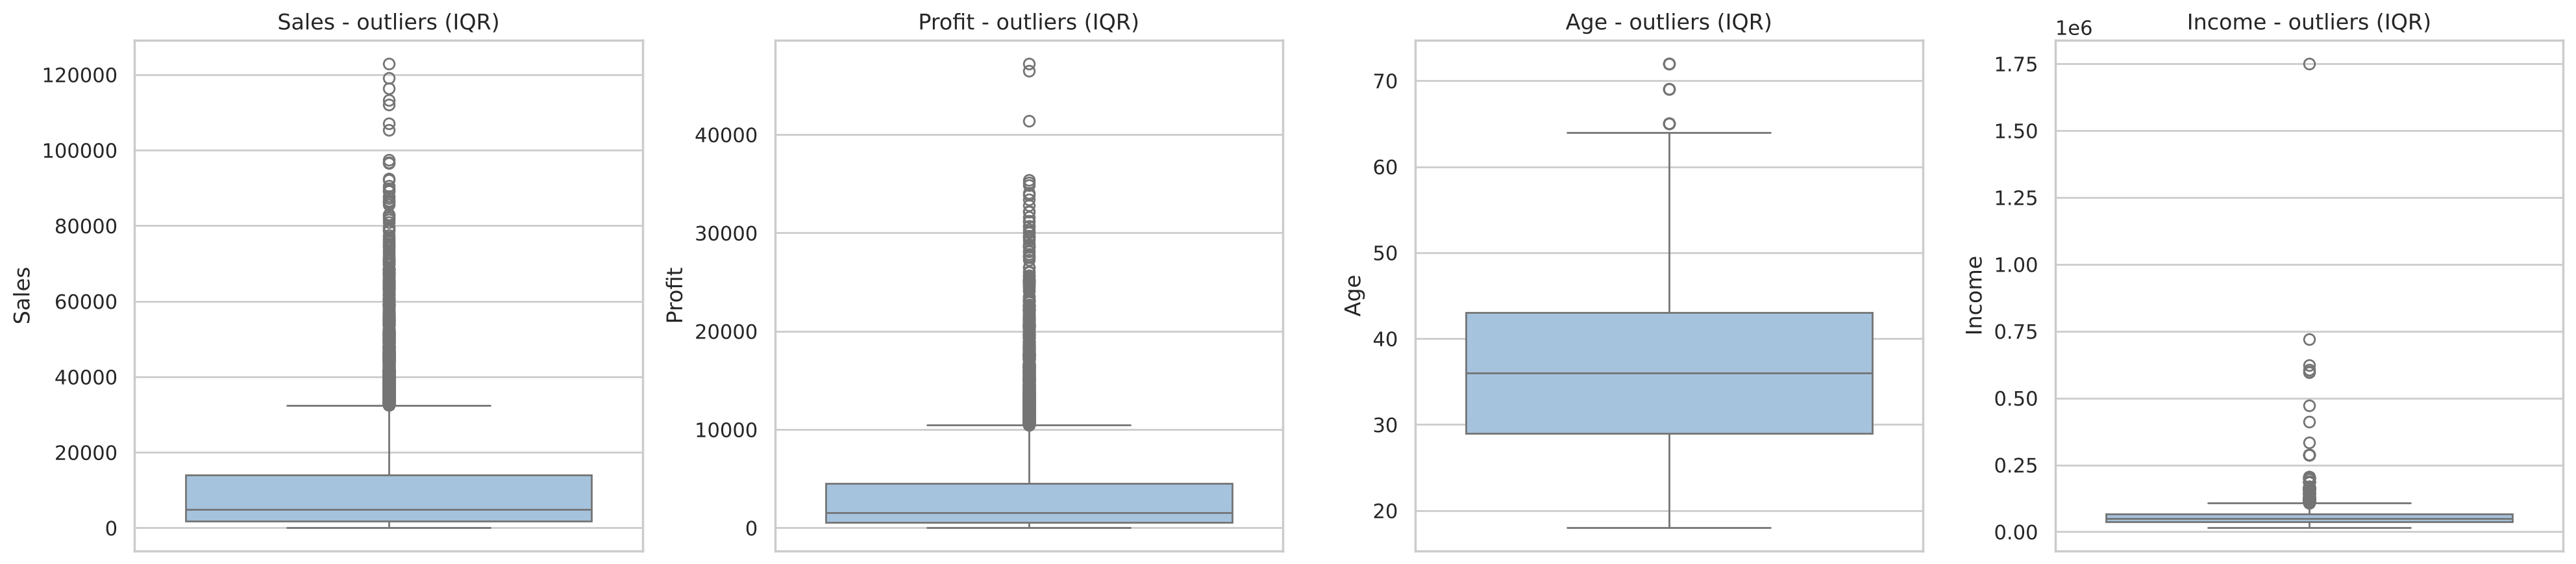

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, c in zip(axes, ['Sales','Profit','Age','Income']):
    sns.boxplot(y=df[c], ax=ax, color='#9DC3E6'); ax.set_title(f'{c} - outliers (IQR)')
plt.tight_layout(); plt.savefig('figures/04_outliers.png', dpi=130); plt.show()

## 6. Feature Engineering and Business Questions

### 6.1 Calculated columns

In [27]:
df['Profit_Margin'] = df.Profit / df.Sales                                   # profit per rupee of sales
df['Delivery_Days'] = (df.Delivery_Date - df.Order_Date).dt.days             # shipping time
df.loc[df.Date_Error_Flag, 'Delivery_Days'] = np.nan                         # impossible -> unknown
df['Revenue_per_Customer'] = df.groupby('Customer_ID').Sales.transform('sum')  # lifetime revenue of this row's customer
df['Order_Year'] = df.Order_Date.dt.year
df['Order_Month'] = df.Order_Date.dt.to_period('M').astype(str)
df['Order_Quarter'] = df.Order_Date.dt.to_period('Q').astype(str)
df['Age_Group'] = pd.cut(df.Age, [17,25,35,45,55,100], labels=['18-25','26-35','36-45','46-55','56+'])
df['Income_Band'] = pd.qcut(df.Income, 4, labels=['Low','Lower-Mid','Upper-Mid','High'])
df['Discount_Band'] = pd.cut(df.Discount, [-0.001,0.05,0.15,0.30,0.50], labels=['0-5%','5-15%','15-30%','30-50%'])
df['Is_Returned'] = (df.Returned == 'Yes').astype(int)
df[['Profit_Margin','Delivery_Days','Revenue_per_Customer','Age_Group','Income_Band','Discount_Band']].describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Profit_Margin,7000.0,NaN,NaN,NaN,0.326281,0.072127,0.200074,0.264578,0.326507,0.390161,0.449994
Delivery_Days,6880.0,NaN,NaN,NaN,5.654651,2.819611,1.0,4.0,6.0,8.0,17.0
Revenue_per_Customer,7000.0,NaN,NaN,NaN,58627.345454,41938.5759,157.81,27254.94,50108.64,80183.94,254002.26
Age_Group,7000,5,36-45,2335,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Income_Band,7000,4,Low,1754,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Discount_Band,7000,4,15-30%,2752,NaN,NaN,NaN,NaN,NaN,NaN,NaN


| New column | Logic | Why useful |
|---|---|---|
| `Profit_Margin` | Profit / Sales | Compares profitability fairly across big and small orders |
| `Delivery_Days` | Delivery_Date - Order_Date (NaN where invalid) | Measures fulfilment speed |
| `Revenue_per_Customer` | Sum of Sales per Customer_ID | Identifies high-value customers |
| `Age_Group`, `Income_Band`, `Discount_Band` | Binning | Enables segment-level comparison |
| `Order_Year/Month/Quarter`, `Is_Returned` | Date parts, Yes/No -> 1/0 | Trend and return-rate analysis |

In [28]:
df.to_csv('outputs/cleaned_retail_customer_sales.csv', index=False)   # re-save including engineered columns
print(df.shape)

(7000, 41)


### 6.2 Business questions (groupby / aggregation)

**Q1. Which region has the highest average order value?**

In [29]:
q1 = df.groupby('Region').agg(orders=('Sales','size'), avg_order_value=('Sales','mean'), total_sales=('Sales','sum')).round(0).sort_values('avg_order_value', ascending=False)
q1

,orders,avg_order_value,total_sales
Region,,,
East,1765,11342.0,20018192.0
West,1798,10989.0,19758996.0
North,1676,10778.0,18063892.0
South,1761,10727.0,18890110.0


**Implication:** East has the highest average order value (~Rs 11,342) and South the lowest (~Rs 10,727), a gap of only ~6%. Regional order sizes are broadly similar, so regional strategy should not be built on basket size; East is a modest upsell/benchmark region.

**Q2. Which product category has the lowest profit margin?** (weighted margin = total profit / total sales)

In [30]:
q2 = df.groupby('Product_Category').agg(sales=('Sales','sum'), profit=('Profit','sum'), avg_margin_per_order=('Profit_Margin','mean'))
q2['weighted_margin_%'] = (q2.profit / q2.sales * 100).round(1)
q2.round(2).sort_values('weighted_margin_%')

,sales,profit,avg_margin_per_order,weighted_margin_%
Product_Category,,,,
Clothing,7781680.39,2521027.84,0.32,32.4
Office Supplies,2566182.51,832190.36,0.33,32.4
Grocery,2685875.10,874840.19,0.32,32.6
Electronics,37639557.39,12352219.50,0.33,32.8
Furniture,26057893.88,8547604.77,0.33,32.8


**Implication:** Weighted margins are almost identical across categories (32.4% to 32.8%). Clothing and Office Supplies are lowest but only by ~0.4 points. Profit therefore comes from *volume of sales*, not from a category with a special margin; the category that sells the most rupees (Electronics, Furniture) also earns the most profit.

**Q3. Which customer segment brings the most revenue and profit?**

In [31]:
q3 = df.groupby('Customer_Segment').agg(orders=('Sales','size'), total_sales=('Sales','sum'), total_profit=('Profit','sum'), avg_order_value=('Sales','mean'))
q3['share_of_sales_%'] = (q3.total_sales / q3.total_sales.sum() * 100).round(1)
q3.round(0).sort_values('total_sales', ascending=False)

,orders,total_sales,total_profit,avg_order_value,share_of_sales_%
Customer_Segment,,,,,
Consumer,3840,41718896.0,13703577.0,10864.0,54.0
Corporate,2114,23551202.0,7665258.0,11141.0,31.0
Home Office,1046,11461090.0,3759047.0,10957.0,15.0


**Implication:** Consumers generate 54% of sales, Corporate 31%, Home Office 15%. Average order values are almost equal (~Rs 10.9-11.1k), so the difference is the *number* of customers/orders, not bigger baskets. Corporate customers do not buy bigger orders here; there is room for a bulk-order or B2B pricing scheme.

**Q4. How do delivery modes compare on speed, rating and returns?**

In [32]:
q4 = df.groupby('Delivery_Mode').agg(orders=('Sales','size'), avg_delivery_days=('Delivery_Days','mean'), avg_rating=('Customer_Rating','mean'), return_rate_pct=('Is_Returned', lambda s: s.mean()*100)).round(2)
q4

,orders,avg_delivery_days,avg_rating,return_rate_pct
Delivery_Mode,,,,
Express,2055,5.63,3.11,12.41
Same-Day,696,5.77,3.12,12.79
Standard,4249,5.65,3.08,12.61


**Implication:** Delivery mode makes **no difference to delivery time**: Express, Same-Day and Standard all take about 5.7 days on average (median 6 days). Customers who pay extra for Express/Same-Day are not receiving a faster service, which is a service-promise and refund risk that needs a logistics review.

**Q5. Does higher discounting hurt margin, and does it raise volume?**

In [33]:
q5 = df.groupby('Discount_Band').agg(orders=('Sales','size'), avg_quantity=('Quantity','mean'), avg_margin=('Profit_Margin','mean'), total_profit=('Profit','sum')).round(3)
q5

,orders,avg_quantity,avg_margin,total_profit
Discount_Band,,,,
0-5%,572,3.056,0.322,2622918.60
5-15%,2352,3.004,0.326,9426574.95
15-30%,2752,3.008,0.328,9626902.01
30-50%,1324,3.004,0.325,3451487.10


**Implication:** Heavier discounts do **not** raise quantity (about 3.0 units in every band) and margin stays about 32-33%. Discounting is therefore not visibly buying extra volume; the 30-50% band covers 1,324 orders that could probably be sold at a lower discount. A discount-caps test is recommended.

**Q6. Which categories and payment methods have the highest return rates?**

In [34]:
q6a = (df.groupby('Product_Category').Is_Returned.mean()*100).round(2).sort_values(ascending=False).to_frame('return_rate_%')
q6b = (df.groupby('Payment_Method').Is_Returned.mean()*100).round(2).sort_values(ascending=False).to_frame('return_rate_%')
display(q6a); display(q6b)

,return_rate_%
Product_Category,
Clothing,13.50
Furniture,13.18
Grocery,12.46
Electronics,12.10
Office Supplies,11.49


,return_rate_%
Payment_Method,
UPI,14.09
Cash on Delivery,13.14
Debit Card,12.14
Net Banking,11.93
Credit Card,11.52


**Implication:** Return rates range from 11.5% to 13.5% across categories (Clothing highest) and from 11.5% (Credit Card) to 14.1% (UPI) across payment methods. Differences are small compared with the link between returns and customer rating (Q10 below).

**Q7. How did sales evolve over time (year-on-year and by quarter)?**

,orders,sales,profit,sales_growth_%
Order_Year,,,,
2023,3525,38655639.0,12509509.0,NaN
2024,3475,38075550.0,12618373.0,-1.5


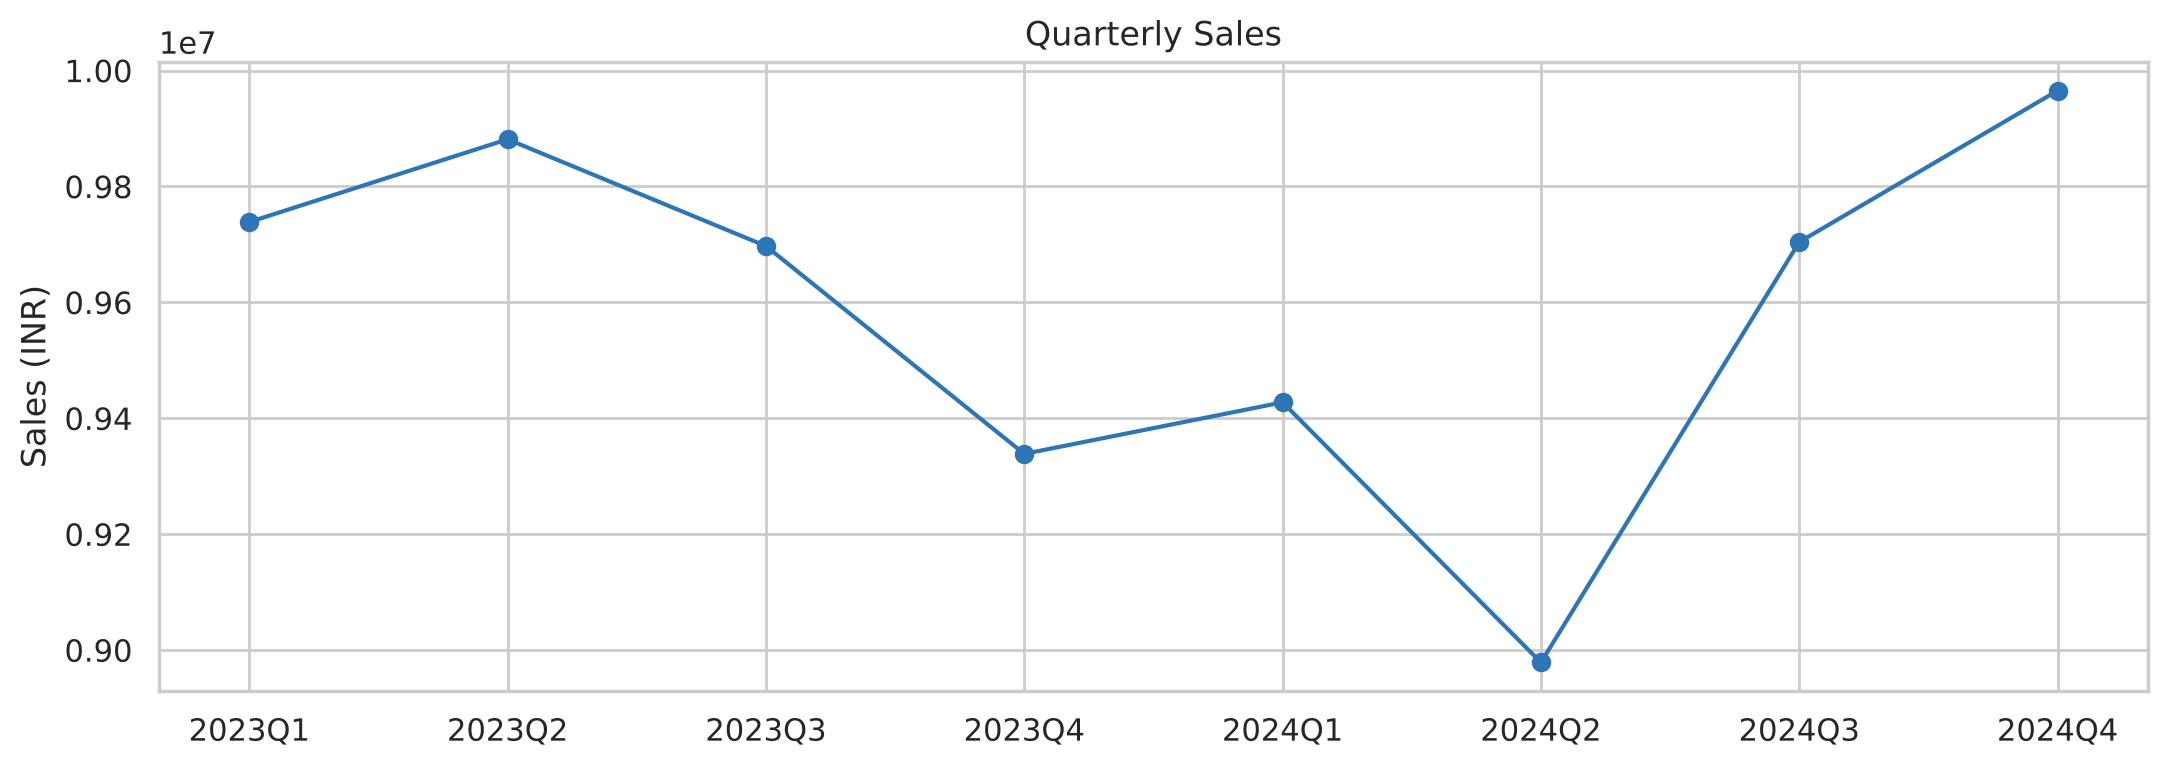

In [35]:
q7 = df.groupby('Order_Year').agg(orders=('Sales','size'), sales=('Sales','sum'), profit=('Profit','sum')).round(0)
q7['sales_growth_%'] = (q7.sales.pct_change()*100).round(1); display(q7)
q7q = df.groupby('Order_Quarter').Sales.sum().round(0)
fig, ax = plt.subplots(figsize=(11,4)); q7q.plot(marker='o', ax=ax, color='#2E75B6'); ax.set_title('Quarterly Sales'); ax.set_ylabel('Sales (INR)'); ax.set_xlabel('')
plt.tight_layout(); plt.savefig('figures/05_quarterly_sales.png', dpi=130); plt.show()

**Implication:** Sales were essentially flat: 2024 was 1.5% lower than 2023, with quarterly sales hovering around Rs 9-10 million and a dip in Q2 2024. There is no growth, so the business is stable but stagnant.

**Q8. How concentrated is revenue among customers (repeat buying)?**

In [36]:
cust = df.groupby('Customer_ID').agg(orders=('Sales','size'), revenue=('Sales','sum')).sort_values('revenue', ascending=False)
top20 = int(len(cust)*0.2)
print('Customers:', len(cust), '| repeat customers (2+ orders): %.1f%%' % ((cust.orders>=2).mean()*100))
print('Top 20%% of customers contribute %.1f%% of revenue' % (cust.revenue.head(top20).sum()/cust.revenue.sum()*100))
cust.head(10).round(0)

Customers: 1576 | repeat customers (2+ orders): 94.5%
Top 20% of customers contribute 44.5% of revenue


,orders,revenue
Customer_ID,,
CUST11430,8,254002.0
CUST10354,11,238065.0
CUST10459,14,221691.0
CUST10302,9,219115.0
CUST10970,6,218119.0
CUST11150,6,213584.0
CUST10594,10,213154.0
CUST10080,10,212963.0
CUST10654,8,192678.0


**Implication:** 94.5% of customers ordered more than once, and the top 20% of customers produce 44.5% of revenue. This is a loyal repeat-buying base, so retention programmes for the top customers protect a large part of revenue.

**Q9. Which Region x Category combination earns the most profit?**

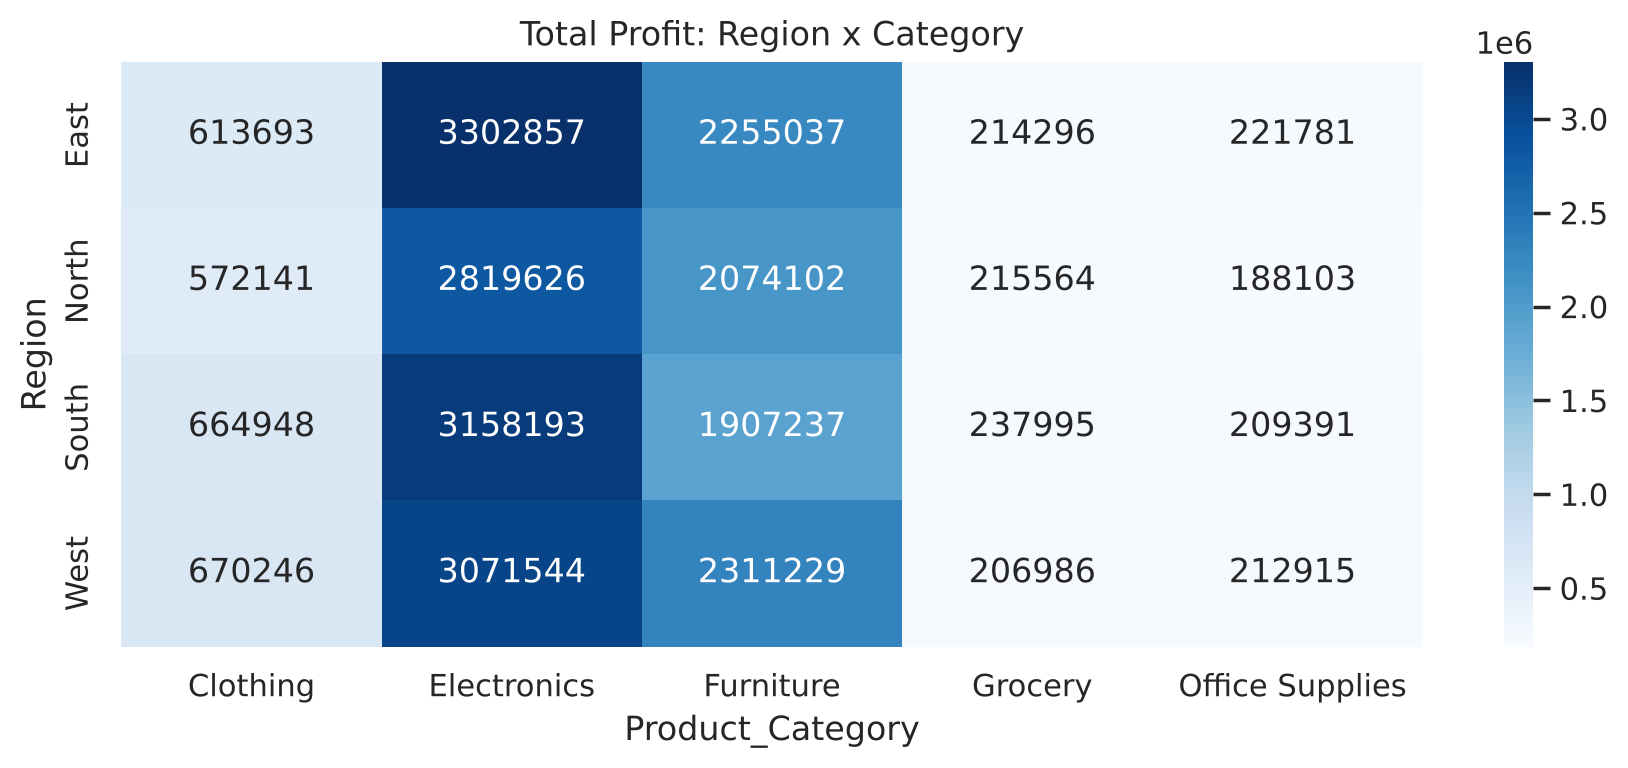

In [ ]:
pt = df.pivot_table(index='Region', columns='Product_Category', values='Profit', aggfunc='sum').round(0)
fig, ax = plt.subplots(figsize=(9,4)); sns.heatmap(pt, annot=True, fmt='.0f', cmap='Blues', ax=ax); ax.set_title('Total Profit: Region x Category')
plt.tight_layout(); plt.savefig('figures/06_region_category_profit.png', dpi=130); plt.show()

**Implication:** Electronics and Furniture are the profit engine in every region; Grocery and Office Supplies add very little profit regardless of region.

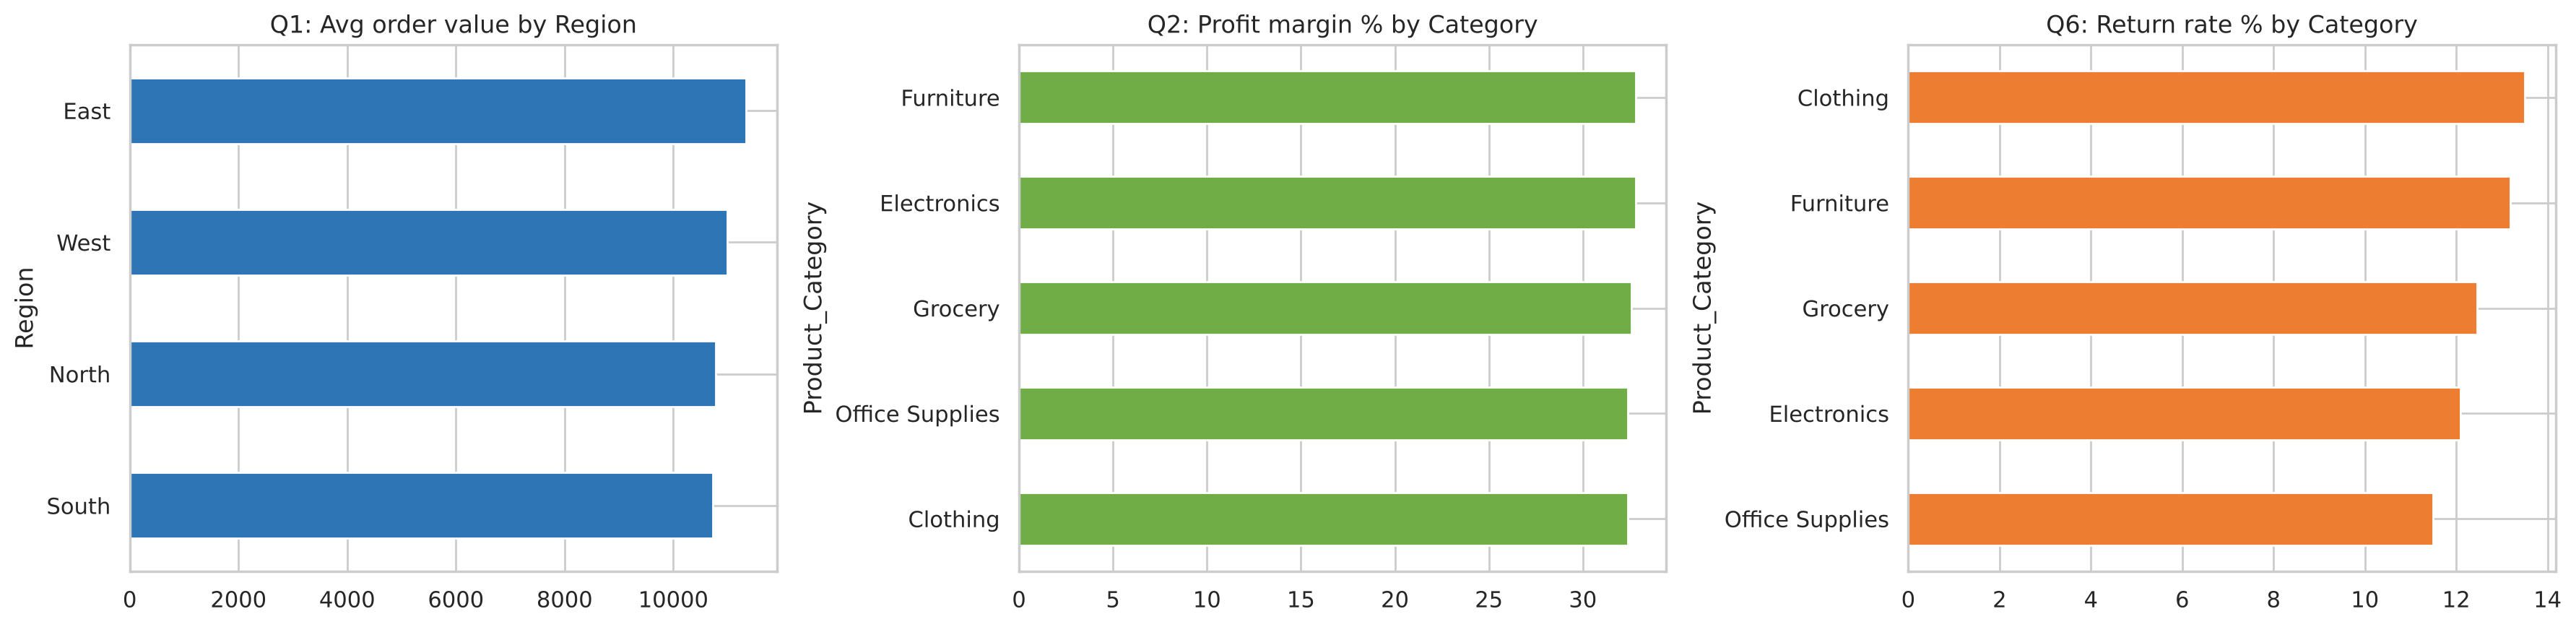

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
q1.avg_order_value.sort_values().plot.barh(ax=axes[0], color='#2E75B6'); axes[0].set_title('Q1: Avg order value by Region')
q2['weighted_margin_%'].sort_values().plot.barh(ax=axes[1], color='#70AD47'); axes[1].set_title('Q2: Profit margin % by Category')
q6a['return_rate_%'].sort_values().plot.barh(ax=axes[2], color='#ED7D31'); axes[2].set_title('Q6: Return rate % by Category')
plt.tight_layout(); plt.savefig('figures/07_business_summary.png', dpi=130); plt.show()

**Q10. How strongly are returns linked to customer rating and satisfaction?**

In [39]:
q10a = (df.groupby('Customer_Rating').Is_Returned.mean()*100).round(1).to_frame('return_rate_%')
q10b = (df.groupby('Satisfaction_Level').Is_Returned.mean()*100).round(1).to_frame('return_rate_%')
display(q10a); display(q10b)
q10c = df.groupby('Product_Category').agg(order_share=('Sales', lambda s: len(s)/len(df)*100), sales_share=('Sales', lambda s: s.sum()/df.Sales.sum()*100)).round(1)
display(q10c)

,return_rate_%
Customer_Rating,
1.0,34.6
2.0,37.6
3.0,3.4
4.0,2.8
5.0,3.3


,return_rate_%
Satisfaction_Level,
High,4.0
Low,27.1
Medium,11.2
Not Provided,12.0


,order_share,sales_share
Product_Category,,
Clothing,21.9,10.1
Electronics,28.2,49.1
Furniture,14.0,34.0
Grocery,23.8,3.5
Office Supplies,12.1,3.3


**Implication:** Orders rated 1-2 stars have 35-38% returns versus about 3% for 3-5 stars; Low satisfaction means a 27% return rate. Returns are the clearest *quality/experience* signal in the data. Also, Electronics and Furniture make up ~83% of sales from only ~42% of orders.

## 7. Key Findings and Business Implications

In [ ]:
print('Overall: %d clean orders | sales Rs %.1f M | profit Rs %.1f M | margin %.1f%% | return rate %.1f%%' % (
  len(df), df.Sales.sum()/1e6,
   df.Profit.sum()/1e6, 
   df.Profit.sum()/df.Sales.sum()*100, 
   df.Is_Returned.mean()*100))
print('Median order Rs %.0f vs mean Rs %.0f' % (df.Sales.median(), 
df.Sales.mean()))

Overall: 7000 clean orders | sales Rs 76.7 M | profit Rs 25.1 M | margin 32.7% | return rate 12.6%
Median order Rs 4826 vs mean Rs 10962


1. **Data was not analysis-ready** - 84 duplicate rows (23 of them hidden behind different spellings/date formats), 8 Gender labels, 12 Region labels, 4 date formats, 6 impossible ages, 6 impossible discounts, 15 deliveries before orders and ~1,200 missing cells. After cleaning: 7,000 unique, consistent transactions.
2. **Typical vs average order** - median order Rs 4,826 vs mean Rs 10,962; a minority of big Electronics/Furniture orders pull the average up.
3. **Two categories carry the business** - Electronics + Furniture = ~83% of sales and profit from ~42% of orders; Grocery/Office Supplies together ~7%.
4. **Margins are flat (~32.7%)** everywhere - across categories, regions, segments and discount bands - so profit follows sales volume, not pricing power.
5. **Discounts do not buy volume** - quantity stays ~3 units from 0-5% to 30-50% discount, so deep discounts look wasteful.
6. **Delivery promise is not met** - Same-Day/Express take as long (median 6 days) as Standard.
7. **Returns signal poor experience** - 35-38% return rate for 1-2 star orders vs ~3% for 3+ stars; 94.5% of customers repeat-buy and top 20% give 44.5% of revenue; sales are flat (-1.5% YoY).

*See the written insights report in `report/` for the plain-language version.*